In [53]:
import numpy as np
import pandas as pd
#loading the data
##Part 1 data cleaning and preparation
DATA_PATH = "h256.csv"

CHRONIC_FLAGS = ["HIBPDX", "CHDDX", "STRKDX", "EMPHDX", "CHOLDX",
                 "CANCERDX", "DIABDX_M18", "ARTHDX", "ASTHDX"]

KEEP = (["DUID", "PERWT24F", "TOTEXP24",
         "AGELAST", "SEX", "RACETHX",
         "INSCOV24", "POVCAT24",
         "RTHLTH53", "MNHLTH53"] + CHRONIC_FLAGS)

df = pd.read_csv(DATA_PATH, usecols=KEEP)
print(df.shape)




##keeping adult with survey weight
df = df[(df["AGELAST"] >= 18) & (df["PERWT24F"] > 0)].copy()
print(len(df))


(19140, 19)
15126


In [54]:
#handeling missing codes
predictor_cols = ["SEX", "RACETHX", "INSCOV24", "POVCAT24",
                  "RTHLTH53", "MNHLTH53"] + CHRONIC_FLAGS
for col in predictor_cols:
    df.loc[df[col] < 0, col] = np.nan


In [55]:
#building crronic condition count
df["chronic_count"] = (df[CHRONIC_FLAGS] == 1).sum(axis=1)
df.loc[df[CHRONIC_FLAGS].isna().any(axis=1), "chronic_count"] = np.nan

In [56]:
#dropping rows with missing values in any of the predictor columns
model_cols = ["AGELAST", "SEX", "RACETHX", "INSCOV24", "POVCAT24",
              "RTHLTH53", "MNHLTH53", "chronic_count"]
n_before = len(df)
df = df.dropna(subset=model_cols).copy()
print(n_before - len(df), "rows dropped;", len(df), "remain")

362 rows dropped; 14764 remain


In [57]:
#making readble version and dummises
df["age"] = df["AGELAST"]
df["female"] = (df["SEX"] == 2).astype(int)
df["ins_public"] = (df["INSCOV24"] == 2).astype(int)
df["ins_uninsured"] = (df["INSCOV24"] == 3).astype(int)
df["race_hispanic"] = (df["RACETHX"] == 1).astype(int)
df["race_black"] = (df["RACETHX"] == 3).astype(int)
df["race_asian"] = (df["RACETHX"] == 4).astype(int)
df["race_other"] = (df["RACETHX"] == 5).astype(int)
df["pov_poor"] = (df["POVCAT24"] == 1).astype(int)
df["pov_near_poor"] = (df["POVCAT24"] == 2).astype(int)
df["pov_low"] = (df["POVCAT24"] == 3).astype(int)
df["pov_middle"] = (df["POVCAT24"] == 4).astype(int)
df["phys_health"] = df["RTHLTH53"]
df["mental_health"] = df["MNHLTH53"]

In [58]:
#creating the target variable

cutoff = df["TOTEXP24"].quantile(0.90)
df["high_cost"] = (df["TOTEXP24"] >= cutoff).astype(int)
print(cutoff, df["high_cost"].mean())

26378.700000000008 0.1000406393931184


In [59]:
FEATURES = ["age", "female",
            "race_hispanic", "race_black", "race_asian", "race_other",
            "ins_public", "ins_uninsured",
            "pov_poor", "pov_near_poor", "pov_low", "pov_middle",
            "chronic_count", "phys_health", "mental_health"]

X = df[FEATURES].astype(float)
y = df["high_cost"]
groups = pd.factorize(df["DUID"])[0]
weights = df["PERWT24F"] / df["PERWT24F"].mean()

In [60]:
#checking the data
print("Adults in sample:", len(df))
print("Households:", df["DUID"].nunique())
print("High-cost share:", round(df["high_cost"].mean(), 3))
print("Missing values in X:", X.isna().sum().sum())

Adults in sample: 14764
Households: 8931
High-cost share: 0.1
Missing values in X: 0


In [61]:
###part 2 exploratory data analysis
import matplotlib.pyplot as plt


In [62]:
summary = X.describe().T[["mean", "std", "min", "max"]].round(3)
print(summary)

                 mean     std   min   max
age            52.847  18.502  18.0  85.0
female          0.530   0.499   0.0   1.0
race_hispanic   0.194   0.395   0.0   1.0
race_black      0.125   0.331   0.0   1.0
race_asian      0.057   0.232   0.0   1.0
race_other      0.031   0.173   0.0   1.0
ins_public      0.335   0.472   0.0   1.0
ins_uninsured   0.070   0.256   0.0   1.0
pov_poor        0.142   0.349   0.0   1.0
pov_near_poor   0.041   0.197   0.0   1.0
pov_low         0.115   0.319   0.0   1.0
pov_middle      0.266   0.442   0.0   1.0
chronic_count   1.635   1.639   0.0   9.0
phys_health     2.486   1.023   1.0   5.0
mental_health   2.344   1.015   1.0   5.0


In [63]:
#Compare high-cost patients with everyone else
compare = df.groupby("high_cost")[FEATURES].mean().T.round(3)
compare.columns = ["not_high_cost", "high_cost"]
print(compare)

               not_high_cost  high_cost
age                   51.763     62.592
female                 0.525      0.575
race_hispanic          0.204      0.107
race_black             0.127      0.103
race_asian             0.060      0.029
race_other             0.031      0.030
ins_public             0.322      0.447
ins_uninsured          0.077      0.006
pov_poor               0.140      0.158
pov_near_poor          0.040      0.045
pov_low                0.114      0.121
pov_middle             0.269      0.238
chronic_count          1.483      3.002
phys_health            2.413      3.148
mental_health          2.308      2.668


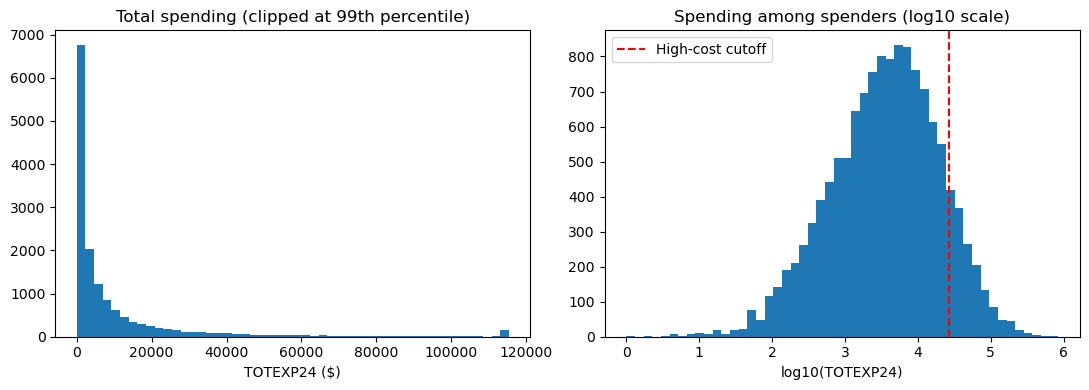

In [64]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].hist(df["TOTEXP24"].clip(upper=df["TOTEXP24"].quantile(0.99)), bins=50)
ax[0].set_title("Total spending (clipped at 99th percentile)")
ax[0].set_xlabel("TOTEXP24 ($)")

pos = df.loc[df["TOTEXP24"] > 0, "TOTEXP24"]
ax[1].hist(np.log10(pos), bins=50)
ax[1].axvline(np.log10(cutoff), color="red", linestyle="--", label="High-cost cutoff")
ax[1].set_title("Spending among spenders (log10 scale)")
ax[1].set_xlabel("log10(TOTEXP24)")
ax[1].legend()

plt.tight_layout()
plt.show()     

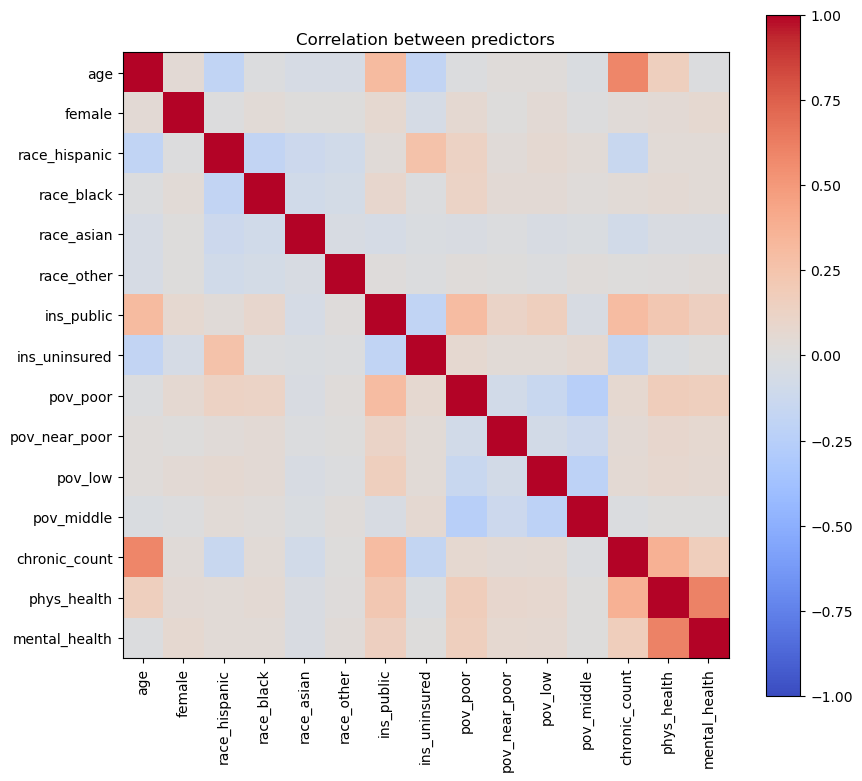

In [65]:
corr = X.corr()
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)))
ax.set_yticks(range(len(FEATURES)))
ax.set_xticklabels(FEATURES, rotation=90)
ax.set_yticklabels(FEATURES)
plt.colorbar(im)
ax.set_title("Correlation between predictors")
plt.tight_layout()
plt.show()

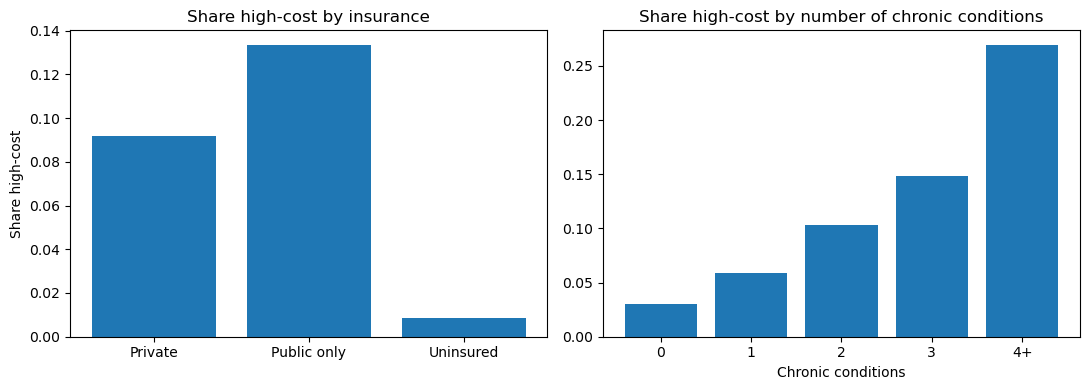

In [66]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# Left: share high-cost by insurance type
ins_labels = {1: "Private", 2: "Public only", 3: "Uninsured"}
rate_ins = df.groupby("INSCOV24")["high_cost"].mean().rename(index=ins_labels)
ax[0].bar(rate_ins.index, rate_ins.values)
ax[0].set_title("Share high-cost by insurance")
ax[0].set_ylabel("Share high-cost")

# Right: share high-cost by number of chronic conditions (4 or more grouped together)
chronic_grp = df["chronic_count"].clip(upper=4).astype(int).astype(str).replace({"4": "4+"})
rate_chr = df.groupby(chronic_grp)["high_cost"].mean()
ax[1].bar(rate_chr.index, rate_chr.values)
ax[1].set_title("Share high-cost by number of chronic conditions")
ax[1].set_xlabel("Chronic conditions")

plt.tight_layout()
plt.show()

In [67]:
## part 3 Assumstion Checks
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [68]:
events = int(y.sum())
print("High-cost patients:", events)
print("Predictors:", len(FEATURES))
print("Events per predictor:", round(events / len(FEATURES)))

High-cost patients: 1477
Predictors: 15
Events per predictor: 98


In [69]:
X_const = sm.add_constant(X)
vif = pd.DataFrame({
    "variable": X_const.columns,
    "VIF": [variance_inflation_factor(X_const.values, i)
            for i in range(X_const.shape[1])]
}).query("variable != 'const'").round(2)
print(vif.to_string(index=False))

     variable  VIF
          age 1.69
       female 1.02
race_hispanic 1.24
   race_black 1.12
   race_asian 1.05
   race_other 1.03
   ins_public 1.46
ins_uninsured 1.18
     pov_poor 1.51
pov_near_poor 1.13
      pov_low 1.27
   pov_middle 1.26
chronic_count 1.77
  phys_health 1.83
mental_health 1.64


In [70]:
#Is each bt = X.copy()
# Is each numeric predictor's effect a straight line? (Box-Tidwell test)
bt = X.copy()
bt["age_x_ln_age"] = bt["age"] * np.log(bt["age"])
bt["chronic_x_ln"] = (bt["chronic_count"] + 1) * np.log(bt["chronic_count"] + 1)

bt_fit = sm.Logit(y, sm.add_constant(bt)).fit(disp=0)
print(bt_fit.pvalues[["age_x_ln_age", "chronic_x_ln"]].round(4))


age_x_ln_age    0.2950
chronic_x_ln    0.3189
dtype: float64


In [71]:

# Check 1: events per predictor
events = int(y.sum())
print("High-cost patients:", events)
print("Predictors:", len(FEATURES))
print("Events per predictor:", round(events / len(FEATURES)))

# Check 4: household independence
hh_size = df.groupby("DUID").size()
print("Households:", len(hh_size))
print("Average adults per household:", round(hh_size.mean(), 2))

# Check 5: strongest correlations between predictors
corr = X.corr()
pairs = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
         .stack().rename("corr").reset_index())
pairs["abs_corr"] = pairs["corr"].abs()
top_pairs = pairs.sort_values("abs_corr", ascending=False).head(6)[["level_0", "level_1", "corr"]]
top_pairs.columns = ["variable_1", "variable_2", "corr"]
print(top_pairs.round(3).to_string(index=False))

High-cost patients: 1477
Predictors: 15
Events per predictor: 98
Households: 8931
Average adults per household: 1.65
   variable_1    variable_2  corr
  phys_health mental_health 0.607
          age chronic_count 0.587
chronic_count   phys_health 0.370
          age    ins_public 0.305
   ins_public      pov_poor 0.302
   ins_public chronic_count 0.298


In [72]:
#Fitting the logistic regression model
#part4



In [73]:
X_sm = sm.add_constant(X)

main = sm.GLM(y, X_sm,
              family=sm.families.Binomial(),
              freq_weights=weights).fit(
              cov_type="cluster", cov_kwds={"groups": groups})

                 coef  odds_ratio  ci_low  ci_high  p_value
const         -4.9337      0.0072  0.0050   0.0104   0.0000
age            0.0143      1.0144  1.0093   1.0195   0.0000
female         0.2530      1.2879  1.1244   1.4751   0.0003
race_hispanic -0.5007      0.6061  0.4797   0.7658   0.0000
race_black    -0.5469      0.5788  0.4574   0.7322   0.0000
race_asian    -0.5315      0.5877  0.4010   0.8614   0.0064
race_other    -0.2551      0.7749  0.4830   1.2431   0.2902
ins_public    -0.2419      0.7851  0.6684   0.9222   0.0032
ins_uninsured -2.0002      0.1353  0.0603   0.3039   0.0000
pov_poor      -0.1933      0.8242  0.6471   1.0497   0.1172
pov_near_poor -0.2732      0.7610  0.5115   1.1322   0.1778
pov_low       -0.2983      0.7421  0.5971   0.9223   0.0072
pov_middle    -0.2492      0.7794  0.6553   0.9271   0.0049
chronic_count  0.3029      1.3538  1.2908   1.4199   0.0000
phys_health    0.5727      1.7731  1.6173   1.9439   0.0000
mental_health -0.0163      0.9838  0.903

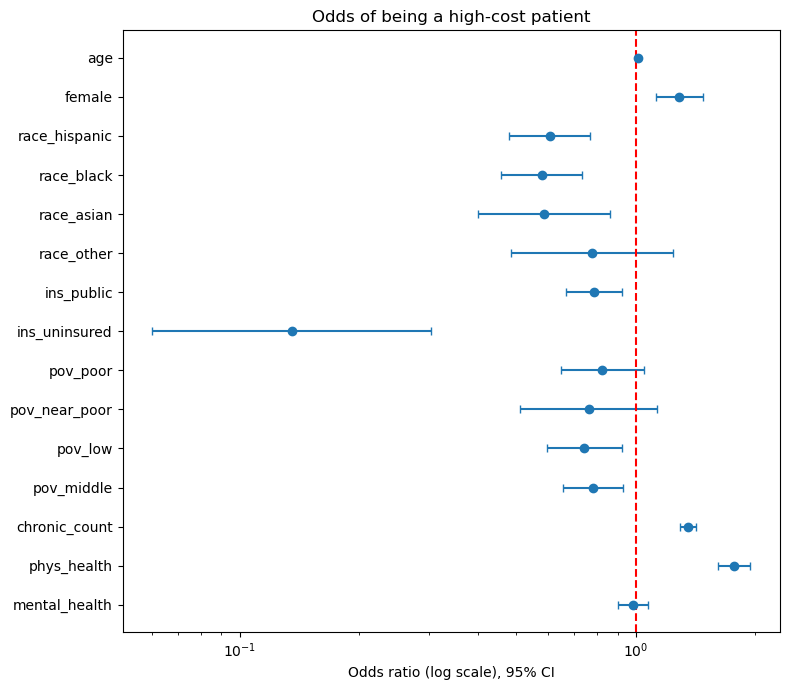

In [74]:
def odds_table(fit):
    ci = fit.conf_int()
    return pd.DataFrame({
        "coef": fit.params,
        "odds_ratio": np.exp(fit.params),
        "ci_low": np.exp(ci[0]),
        "ci_high": np.exp(ci[1]),
        "p_value": fit.pvalues,
    }).round(4)

tab_main = odds_table(main)
print(tab_main)





# H1 test: uninsured vs privately insured
b = main.params["ins_uninsured"]
p_two = main.pvalues["ins_uninsured"]
p_one = p_two / 2 if b < 0 else 1 - p_two / 2

print("coefficient:", round(b, 3))

print("odds ratio:", round(np.exp(b), 3))
print("95% CI:", round(tab_main.loc["ins_uninsured", "ci_low"], 3),
      "to", round(tab_main.loc["ins_uninsured", "ci_high"], 3))
print("two-sided p:", round(p_two, 4))
print("one-sided p (H1: below 1):", round(p_one, 4))
print("Decision:", "reject H0" if p_one < 0.05 else "fail to reject H0")

check_fit = sm.GLM(y, X_sm, family=sm.families.Binomial()).fit(
    cov_type="cluster", cov_kwds={"groups": groups})

print("Unweighted odds ratio:", round(np.exp(check_fit.params["ins_uninsured"]), 3))
print("Unweighted p:", round(check_fit.pvalues["ins_uninsured"], 4))
plot_tab = tab_main.drop(index="const").iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 7))
ax.errorbar(plot_tab["odds_ratio"], range(len(plot_tab)),
            xerr=[plot_tab["odds_ratio"] - plot_tab["ci_low"],
                  plot_tab["ci_high"] - plot_tab["odds_ratio"]],
            fmt="o", capsize=3)
ax.axvline(1, color="red", linestyle="--")
ax.set_yticks(range(len(plot_tab)))
ax.set_yticklabels(plot_tab.index)
ax.set_xscale("log")
ax.set_xlabel("Odds ratio (log scale), 95% CI")
ax.set_title("Odds of being a high-cost patient")
plt.tight_layout()
plt.savefig("fig_odds_ratios.png", dpi=150, bbox_inches="tight")
plt.show()


In [75]:
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, StratifiedGroupKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             precision_score, recall_score, f1_score,
                             roc_curve, precision_recall_curve, confusion_matrix)

In [76]:
# Split by household
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print("Train:", len(X_train), "rows, share high-cost:", round(y_train.mean(), 3))
print("Test: ", len(X_test), "rows, share high-cost:", round(y_test.mean(), 3))

Train: 11751 rows, share high-cost: 0.103
Test:  3013 rows, share high-cost: 0.09


In [77]:
models = {
    "Logistic": make_pipeline(StandardScaler(), LogisticRegression(C=1e6, max_iter=2000)),
    "NaiveBayes": GaussianNB(),
}

In [78]:
prevalence = y_test.mean()
rows, curves = [], {}

for name, model in models.items():
    model.fit(X_train, y_train)

    # Predicted chance of being high-cost for each test person
    p = model.predict_proba(X_test)[:, 1]

    # Flag as high-cost if the chance is 50% or more
    pred_05 = (p >= 0.5).astype(int)

    # Flag the 10% of people with the highest predicted risk
    top_cut = np.quantile(p, 0.90)
    pred_top = (p >= top_cut).astype(int)

    rows.append({
        "model": name,
        "ROC_AUC": roc_auc_score(y_test, p),
        "PR_AUC": average_precision_score(y_test, p),
        "Brier": brier_score_loss(y_test, p),
        "precision@0.5": precision_score(y_test, pred_05, zero_division=0),
        "recall@0.5": recall_score(y_test, pred_05),
        "F1@0.5": f1_score(y_test, pred_05),
        "precision@top10%": precision_score(y_test, pred_top, zero_division=0),
        "recall@top10%": recall_score(y_test, pred_top),
    })
    curves[name] = p

    print(f"\n{name} confusion matrix at 0.5 (rows = actual, cols = predicted):")
    print(confusion_matrix(y_test, pred_05))

results = pd.DataFrame(rows).set_index("model").round(3)
print("\nTEST-SET PERFORMANCE")
print(results.T)
print(f"\nBaselines: 'always say no' accuracy = {1 - prevalence:.3f}; "
      f"random PR_AUC = {prevalence:.3f}; random ROC_AUC = 0.500")


Logistic confusion matrix at 0.5 (rows = actual, cols = predicted):
[[2731   12]
 [ 257   13]]

NaiveBayes confusion matrix at 0.5 (rows = actual, cols = predicted):
[[2166  577]
 [  98  172]]

TEST-SET PERFORMANCE
model             Logistic  NaiveBayes
ROC_AUC              0.807       0.790
PR_AUC               0.304       0.303
Brier                0.071       0.156
precision@0.5        0.520       0.230
recall@0.5           0.048       0.637
F1@0.5               0.088       0.338
precision@top10%     0.344       0.308
recall@top10%        0.385       0.344

Baselines: 'always say no' accuracy = 0.910; random PR_AUC = 0.090; random ROC_AUC = 0.500


In [79]:
prevalence = y_test.mean()
rows, curves = [], {}

for name, model in models.items():
    model.fit(X_train, y_train)

    # Predicted chance of being high-cost for each test person
    p = model.predict_proba(X_test)[:, 1]

    # Flag as high-cost if the chance is 50% or more
    pred_05 = (p >= 0.5).astype(int)

    # Flag the 10% of people with the highest predicted risk
    top_cut = np.quantile(p, 0.90)
    pred_top = (p >= top_cut).astype(int)

    rows.append({
        "model": name,
        "ROC_AUC": roc_auc_score(y_test, p),
        "PR_AUC": average_precision_score(y_test, p),
        "Brier": brier_score_loss(y_test, p),
        "precision@0.5": precision_score(y_test, pred_05, zero_division=0),
        "recall@0.5": recall_score(y_test, pred_05),
        "F1@0.5": f1_score(y_test, pred_05),
        "precision@top10%": precision_score(y_test, pred_top, zero_division=0),
        "recall@top10%": recall_score(y_test, pred_top),
    })
    curves[name] = p

    print(f"\n{name} confusion matrix at 0.5 (rows = actual, cols = predicted):")
    print(confusion_matrix(y_test, pred_05))

results = pd.DataFrame(rows).set_index("model").round(3)
print("\nTEST-SET PERFORMANCE")
print(results.T)
print(f"\nBaselines: 'always say no' accuracy = {1 - prevalence:.3f}; "
      f"random PR_AUC = {prevalence:.3f}; random ROC_AUC = 0.500")


Logistic confusion matrix at 0.5 (rows = actual, cols = predicted):
[[2731   12]
 [ 257   13]]

NaiveBayes confusion matrix at 0.5 (rows = actual, cols = predicted):
[[2166  577]
 [  98  172]]

TEST-SET PERFORMANCE
model             Logistic  NaiveBayes
ROC_AUC              0.807       0.790
PR_AUC               0.304       0.303
Brier                0.071       0.156
precision@0.5        0.520       0.230
recall@0.5           0.048       0.637
F1@0.5               0.088       0.338
precision@top10%     0.344       0.308
recall@top10%        0.385       0.344

Baselines: 'always say no' accuracy = 0.910; random PR_AUC = 0.090; random ROC_AUC = 0.500


            CV_AUC_mean  CV_AUC_sd
model                             
Logistic          0.782      0.006
NaiveBayes        0.755      0.012


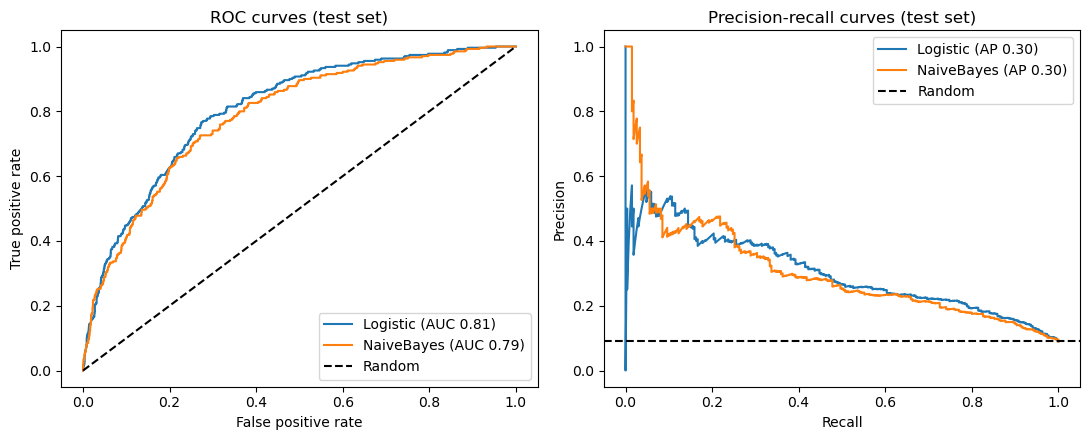

In [80]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []

for name, model in models.items():
    aucs = []
    for tr, te in cv.split(X, y, groups):
        model.fit(X.iloc[tr], y.iloc[tr])
        aucs.append(roc_auc_score(y.iloc[te], model.predict_proba(X.iloc[te])[:, 1]))
    cv_rows.append({"model": name, "CV_AUC_mean": np.mean(aucs), "CV_AUC_sd": np.std(aucs)})

cv_results = pd.DataFrame(cv_rows).set_index("model").round(3)
print(cv_results)
# Refit on the original training set (cross-validation refit the models on the last fold)
for name, model in models.items():
    model.fit(X_train, y_train)
    curves[name] = model.predict_proba(X_test)[:, 1]

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

for name, p in curves.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, p):.2f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    ax[1].plot(rec, prec, label=f"{name} (AP {average_precision_score(y_test, p):.2f})")

ax[0].plot([0, 1], [0, 1], "k--", label="Random")
ax[0].set_xlabel("False positive rate")
ax[0].set_ylabel("True positive rate")
ax[0].set_title("ROC curves (test set)")
ax[0].legend()

ax[1].axhline(prevalence, color="k", linestyle="--", label="Random")
ax[1].set_xlabel("Recall")
ax[1].set_ylabel("Precision")
ax[1].set_title("Precision-recall curves (test set)")
ax[1].legend()

plt.tight_layout()
plt.savefig("fig_roc_pr_curves.png", dpi=150, bbox_inches="tight")
plt.show()

In [38]:
for name, model in models.items():
    model.fit(X_train, y_train)

In [39]:
check = pd.DataFrame({
    "actual_high_cost": y_test.values[:10],
    "age": X_test["age"].values[:10],
    "chronic_count": X_test["chronic_count"].values[:10],
})

for name, model in models.items():
    check[name + "_chance"] = model.predict_proba(X_test.iloc[:10])[:, 1].round(3)

print(check)

   actual_high_cost   age  chronic_count  Logistic_chance  NaiveBayes_chance
0                 0  67.0            2.0            0.152              0.767
1                 0  43.0            2.0            0.036              0.000
2                 1  63.0            5.0            0.243              0.760
3                 0  28.0            2.0            0.133              0.276
4                 0  28.0            0.0            0.037              0.037
5                 0  83.0            3.0            0.121              0.484
6                 0  41.0            0.0            0.050              0.065
7                 0  45.0            0.0            0.053              0.084
8                 0  35.0            0.0            0.041              0.037
9                 0  56.0            0.0            0.052              0.113


In [40]:
new_person = pd.DataFrame([{
    "age": 65, "female": 1,
    "race_hispanic": 0, "race_black": 0, "race_asian": 0, "race_other": 0,
    "ins_public": 1, "ins_uninsured": 0,
    "pov_poor": 0, "pov_near_poor": 0, "pov_low": 1, "pov_middle": 0,
    "chronic_count": 4, "phys_health": 4, "mental_health": 3
}])[FEATURES]

for name, model in models.items():
    print(name, "chance of being high-cost:", round(model.predict_proba(new_person)[0, 1], 3))

Logistic chance of being high-cost: 0.299
NaiveBayes chance of being high-cost: 0.945


In [43]:
df

,DUID,AGELAST,SEX,RACETHX,HIBPDX,CHDDX,STRKDX,EMPHDX,CHOLDX,CANCERDX,...,race_black,race_asian,race_other,pov_poor,pov_near_poor,pov_low,pov_middle,phys_health,mental_health,high_cost
0,2810003,67,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,...,0,0,0,0,0,0,0,3.0,4.0,0
1,2810006,47,2.0,3.0,2.0,2.0,2.0,2.0,2.0,2.0,...,1,0,0,0,0,0,0,1.0,2.0,0
2,2810006,51,1.0,3.0,2.0,2.0,2.0,2.0,2.0,2.0,...,1,0,0,0,0,0,0,2.0,2.0,0
4,2810006,20,1.0,3.0,2.0,2.0,2.0,2.0,2.0,2.0,...,1,0,0,0,0,0,0,1.0,2.0,0
5,2810007,65,2.0,3.0,1.0,2.0,1.0,2.0,1.0,2.0,...,1,0,0,0,0,0,1,3.0,3.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19130,2930417,83,1.0,3.0,1.0,2.0,2.0,2.0,2.0,2.0,...,1,0,0,0,0,0,1,4.0,1.0,1
19133,2930420,57,2.0,3.0,1.0,2.0,2.0,2.0,1.0,2.0,...,1,0,0,0,0,1,0,3.0,4.0,0
19134,2930421,38,2.0,1.0,2.0,2.0,2.0,2.0,1.0,2.0,...,0,0,0,0,0,0,1,1.0,3.0,0
19135,2930421,48,1.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,...,0,0,0,0,0,0,1,3.0,3.0,0


In [44]:
df[CHRONIC_FLAGS]

,HIBPDX,CHDDX,STRKDX,EMPHDX,CHOLDX,CANCERDX,DIABDX_M18,ARTHDX,ASTHDX
0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,2.0
1,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0
2,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0
4,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0
5,1.0,2.0,1.0,2.0,1.0,2.0,2.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...
19130,1.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0
19133,1.0,2.0,2.0,2.0,1.0,2.0,1.0,1.0,2.0
19134,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0
19135,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0


In [47]:
df['age']

0        67
1        47
2        51
4        20
5        65
         ..
19130    83
19133    57
19134    38
19135    48
19139    19
Name: age, Length: 14764, dtype: int64

In [48]:
df['AGELAST']

0        67
1        47
2        51
4        20
5        65
         ..
19130    83
19133    57
19134    38
19135    48
19139    19
Name: AGELAST, Length: 14764, dtype: int64